# Практика 1. S3: хранилище для данных и моделей

**Перед началом:** этот файл только для чтения и общий для всей группы.
Сохраните свою копию: **File → Save Notebook As…** →
`work/students/<ваше_имя>/01_s3.ipynb` и работайте в ней.

План:
1. Установка библиотек
2. Подключение к S3
3. Свой бакет
4. Загрузка файлов в S3
5. Просмотр содержимого
6. Скачивание файлов
7. Таблицы pandas и модели в S3
8. Копирование, удаление, ссылка для скачивания
9. **Задачи**

## 1. Установка библиотек

- **boto3** — официальный клиент S3 для Python (от Amazon, работает с любым S3-совместимым хранилищем)
- **s3fs** — даёт pandas читать и писать по адресу `s3://…`

На нашем сервере они уже стоят, команда просто это проверит. На своём компьютере она их установит.

In [ ]:
%pip install -q boto3 s3fs pandas pyarrow matplotlib scikit-learn joblib


[notice] A new release of pip is available: 24.0 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


^C
Note: you may need to restart the kernel to use updated packages.


In [13]:
import boto3
print("boto3", boto3.__version__)

boto3 1.43.109


## 2. Подключение к S3

Чтобы подключиться, нужны три вещи:

| Что | Где взять |
|---|---|
| адрес хранилища (`endpoint_url`) | внутри сервера `http://s3:9000`, снаружи `http://10.162.1.86:9000` |
| логин (`aws_access_key_id`) | ваш логин S3: `user1` … `user30` (выдаёт преподаватель) |
| пароль (`aws_secret_access_key`) | выдаёт преподаватель |

**Пароль никогда не пишем в код** — код попадает в Git и в чужие руки. Вводим его через `getpass`:
он спрашивается при запуске ячейки и нигде не сохраняется.

In [14]:
from getpass import getpass

S3_URL = "http://localhost:9000"
print("Адрес S3:", S3_URL)

Адрес S3: http://localhost:9000


In [15]:
from botocore.config import Config

S3_USER = "user1"
S3_PASSWORD = getpass("Введи пароль S3 из файла .env: ")

s3 = boto3.client(
    "s3",
    endpoint_url=S3_URL,
    aws_access_key_id=S3_USER,
    aws_secret_access_key=S3_PASSWORD,
    region_name="us-east-1",
    config=Config(
        signature_version="s3v4",
        s3={"addressing_style": "path"},
    ),
)

for b in s3.list_buckets()["Buckets"]:
    print(b["Name"], b["CreationDate"].date())

mlflow 2026-10-08
user1 2026-10-08


## 3. Свой бакет

Бакет — большой контейнер с уникальным именем. У каждого студента свой: **имя бакета = ваш логин** (`user7` → бакет `user7`).

Бакет уже создан для вас заранее. Права настроены так, что вы видите и можете делать всё **только в своём бакете**.
Создать бакет с другим именем или заглянуть в чужой нельзя — сервер ответит `AccessDenied`. Это и есть разграничение доступа в S3.

In [16]:
BUCKET = S3_USER
print("мой бакет:", BUCKET)

мой бакет: user1


In [17]:
from botocore.exceptions import ClientError

def bucket_exists(name: str) -> bool:
    try:
        s3.head_bucket(Bucket=name)   # head_* — узнать, есть ли объект, не скачивая его
        return True
    except ClientError:
        return False

if not bucket_exists(BUCKET):
    s3.create_bucket(Bucket=BUCKET)
    print("создан бакет", BUCKET)
else:
    print("бакет уже есть:", BUCKET)

бакет уже есть: user1


In [18]:
# попробуем заглянуть в чужой бакет — должно быть запрещено
try:
    s3.list_objects_v2(Bucket="students")
    print("доступ есть?!")
except ClientError as e:
    print("чужой бакет:", e.response["Error"]["Code"])

чужой бакет: NoSuchBucket


## 4. Загрузка файлов в S3

Три способа:

| Метод | Когда |
|---|---|
| `upload_file(путь, бакет, ключ)` | файл уже лежит на диске |
| `put_object(Bucket, Key, Body)` | данные в памяти: строка или байты |
| `upload_fileobj(файл, бакет, ключ)` | открытый файл или поток |

**Ключ** — полное имя объекта. Слеши в ключе выглядят как папки, но это просто часть имени.

In [ ]:
# 4.1 файл с диска
with open("hello.txt", "w", encoding="utf-8") as f:
    f.write("Привет, S3!\n")

with open("hello_downloaded.txt", encoding="utf-8") as f:
    print(f.read())

загружен docs/hello.txt


In [20]:
# 4.2 строка из памяти, без файла на диске
s3.put_object(Bucket=BUCKET, Key="docs/note.txt", Body="Заметка из памяти".encode("utf-8"))
print("загружен docs/note.txt")

загружен docs/note.txt


In [24]:
# 4.3 таблица pandas -> CSV в S3
import pandas as pd
from sklearn.datasets import load_wine

wine = load_wine(as_frame=True).frame
s3.put_object(Bucket=BUCKET, Key="data/raw/wine.csv", Body=wine.to_csv(index=False))
print("загружен data/raw/wine.csv:", wine.shape)

загружен data/raw/wine.csv: (178, 14)


In [25]:
# 4.4 картинка matplotlib -> PNG в S3 (через память, без диска)
import io
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(6, 3))
wine["alcohol"].hist(ax=ax, bins=20)
ax.set_title("Алкоголь в винах")

buf = io.BytesIO()
fig.savefig(buf, format="png", dpi=100)
plt.close(fig)
s3.put_object(Bucket=BUCKET, Key="images/alcohol.png", Body=buf.getvalue(), ContentType="image/png")
print("загружен images/alcohol.png,", len(buf.getvalue()), "байт")

загружен images/alcohol.png, 13753 байт


## 5. Что лежит в бакете

`list_objects_v2` возвращает до 1000 объектов. `Prefix` — показать только ключи, начинающиеся с этой строки («папка»).

In [26]:
def ls(prefix: str = ""):
    resp = s3.list_objects_v2(Bucket=BUCKET, Prefix=prefix)
    for obj in resp.get("Contents", []):
        print(f'{obj["Key"]:<30} {obj["Size"]:>8} байт   {obj["LastModified"]:%Y-%m-%d %H:%M}')

ls()

data/raw/wine.csv                 12440 байт   2026-10-08 14:00
docs/hello.txt                       13 байт   2026-10-08 13:58
docs/note.txt                        32 байт   2026-10-08 13:58
images/alcohol.png                13753 байт   2026-10-08 14:00


In [27]:
ls("docs/")   # только «папка» docs

docs/hello.txt                       13 байт   2026-10-08 13:58
docs/note.txt                        32 байт   2026-10-08 13:58


In [28]:
# метаданные одного объекта, без скачивания
meta = s3.head_object(Bucket=BUCKET, Key="images/alcohol.png")
print(meta["ContentLength"], "байт,", meta["ContentType"])

13753 байт, image/png


## 6. Скачивание

| Метод | Результат |
|---|---|
| `download_file(бакет, ключ, путь)` | файл на диске |
| `get_object(Bucket, Key)["Body"].read()` | байты в памяти |

In [29]:
# 6.1 на диск
s3.download_file(BUCKET, "docs/hello.txt", "hello_downloaded.txt")
print(open("hello_downloaded.txt").read())

Привет, S3!



In [30]:
# 6.2 в память
body = s3.get_object(Bucket=BUCKET, Key="docs/note.txt")["Body"].read()
print(body.decode("utf-8"))

Заметка из памяти


In [31]:
# 6.3 CSV из S3 сразу в pandas
body = s3.get_object(Bucket=BUCKET, Key="data/raw/wine.csv")["Body"].read()
df = pd.read_csv(io.BytesIO(body))
df.head()

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,target
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,0


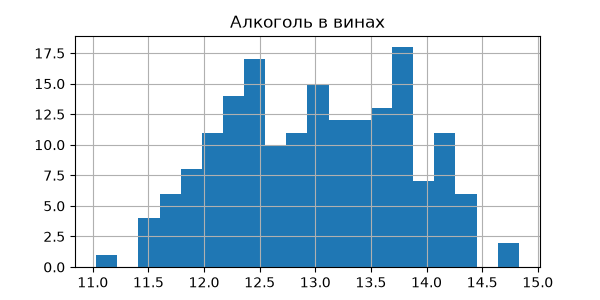

In [32]:
# 6.4 картинку из S3 — показать в ноутбуке
from IPython.display import Image
Image(s3.get_object(Bucket=BUCKET, Key="images/alcohol.png")["Body"].read())

## 7. Parquet и модели в S3

### Зачем это нужно
В ML-конвейере данные сохраняют **много раз**: сырые → очищенные → train/test → прогнозы.
Если каждый раз сохранять в CSV, возникают три проблемы:

1. **Размер.** CSV — это текст: число `300.25` занимает 6 байт, в parquet — меньше и ещё сжимается.
2. **Скорость.** CSV нужно разбирать построчно, parquet читается почти сразу.
3. **Типы теряются.** Сохранили дату в CSV — прочитали обратно **строку**. Parquet помнит, что это дата.

**Parquet** — формат таблиц, который решает все три проблемы. Поэтому в ML его используют почти везде
(в наших DAG-ах train/test тоже лежат в `.parquet`).

### Что сделаем
- **7.1** — сравним CSV и parquet на таблице продаж в **миллион строк** (как в примере с магазином из лекции);
- **7.2** — научимся класть таблицу в S3 в parquet и читать обратно: это приём, который вы будете использовать в Airflow;
- **7.3** — так же сохраним в S3 **модель**.

In [33]:
# 7.1 CSV против parquet на большой таблице (всё в памяти, в S3 пока не пишем)
import time
import numpy as np

n = 1_000_000
rng = np.random.default_rng(42)
sales = pd.DataFrame({
    "time": pd.date_range("2026-01-01", periods=n, freq="min"),   # дата и время продажи
    "store": rng.choice(["Москва", "Казань", "Сочи"], n),
    "product_id": rng.integers(1, 5000, n),
    "price": rng.normal(300, 50, n).round(2),
    "sold": rng.integers(0, 20, n),
})

csv_bytes = sales.to_csv(index=False).encode()        # таблица -> CSV (байты)
pq_buf = io.BytesIO()
sales.to_parquet(pq_buf, index=False)                  # таблица -> parquet (байты)
pq_bytes = pq_buf.getvalue()

t = time.time(); from_csv = pd.read_csv(io.BytesIO(csv_bytes)); t_csv = time.time() - t
t = time.time(); from_pq = pd.read_parquet(io.BytesIO(pq_bytes)); t_pq = time.time() - t

print(f"Размер:  CSV {len(csv_bytes)/1e6:.1f} МБ   parquet {len(pq_bytes)/1e6:.1f} МБ   (в {len(csv_bytes)/len(pq_bytes):.1f} раза меньше)")
print(f"Чтение:  CSV {t_csv:.2f} с     parquet {t_pq:.2f} с")
print("Тип колонки time после CSV:    ", from_csv["time"].dtype, " <- строка, дату надо разбирать заново")
print("Тип колонки time после parquet:", from_pq["time"].dtype)

Размер:  CSV 46.8 МБ   parquet 10.9 МБ   (в 4.3 раза меньше)
Чтение:  CSV 0.93 с     parquet 0.31 с
Тип колонки time после CSV:     str  <- строка, дату надо разбирать заново
Тип колонки time после parquet: datetime64[us]


**Что видно:** parquet в несколько раз меньше, читается во много раз быстрее, и дата осталась датой.
Для ML это значит: меньше места в S3, быстрее задачи Airflow и нет ошибок из-за «испорченных» типов.

Ещё один плюс — можно прочитать **только нужные колонки**, не загружая всю таблицу:

In [34]:
t = time.time()
only_sold = pd.read_parquet(io.BytesIO(pq_bytes), columns=["sold"])
print(f"одна колонка из миллиона строк: {time.time() - t:.3f} с")

одна колонка из миллиона строк: 0.011 с


> На маленькой таблице (150–200 строк, как Iris или Wine) parquet может оказаться даже **больше** CSV:
> в файле есть служебная информация о колонках. Выигрыш появляется на больших данных — а в реальных задачах они большие.

### 7.2 Таблица в S3 в формате parquet и обратно
Схема всегда одна и та же, её стоит запомнить:

**сохранить:** DataFrame → `to_parquet` в буфер памяти → `put_object`<br>
**прочитать:** `get_object` → байты → `read_parquet`

In [35]:
# сохранить: DataFrame -> parquet в памяти -> S3
buf = io.BytesIO()
sales.to_parquet(buf, index=False)
s3.put_object(Bucket=BUCKET, Key="data/processed/sales.parquet", Body=buf.getvalue())

# прочитать: S3 -> байты -> DataFrame
body = s3.get_object(Bucket=BUCKET, Key="data/processed/sales.parquet")["Body"].read()
sales_back = pd.read_parquet(io.BytesIO(body))

print("в S3:", s3.head_object(Bucket=BUCKET, Key="data/processed/sales.parquet")["ContentLength"] // 1_000_000, "МБ")
print("прочитали", sales_back.shape, "| совпадает с исходной:", sales_back.equals(sales))

в S3: 10 МБ
прочитали (1000000, 5) | совпадает с исходной: True


### 7.3 Модель в S3
Модель sklearn — это объект Python, а S3 хранит байты. `joblib.dump` превращает модель в байты,
`joblib.load` — обратно. Так модель, обученную в одной задаче Airflow, загружает следующая задача
или сервис прогнозов на другом компьютере.

In [36]:
import joblib
from sklearn.linear_model import LogisticRegression

X, y = wine.drop(columns="target"), wine["target"]
model = LogisticRegression(max_iter=5000).fit(X, y)

buf = io.BytesIO()
joblib.dump(model, buf)                                         # модель -> байты
s3.put_object(Bucket=BUCKET, Key="models/logreg.joblib", Body=buf.getvalue())

body = s3.get_object(Bucket=BUCKET, Key="models/logreg.joblib")["Body"].read()
loaded = joblib.load(io.BytesIO(body))                          # байты -> модель
print("прогноз загруженной модели:", loaded.predict(X.head(5)))

прогноз загруженной модели: [0 0 0 0 0]


## 8. Копирование, удаление, ссылка для скачивания

In [37]:
# 8.1 копия внутри S3 (данные не проходят через ваш компьютер)
s3.copy_object(Bucket=BUCKET, Key="backup/wine.csv",
               CopySource={"Bucket": BUCKET, "Key": "data/raw/wine.csv"})
ls("backup/")

backup/wine.csv                   12440 байт   2026-10-08 14:03


In [38]:
# 8.2 удаление
s3.delete_object(Bucket=BUCKET, Key="backup/wine.csv")
ls("backup/")
print("после удаления в backup/ пусто")

после удаления в backup/ пусто


In [40]:
# 8.3 временная ссылка на файл (presigned URL): открывается в браузере без пароля, пока не истечёт
public = boto3.client("s3", endpoint_url="http://localhost:9000",   # адрес, видимый снаружи
                      aws_access_key_id=S3_USER, aws_secret_access_key=S3_PASSWORD)
url = public.generate_presigned_url("get_object",
                                    Params={"Bucket": BUCKET, "Key": "images/alcohol.png"},
                                    ExpiresIn=600)   # 10 минут
print(url)

http://localhost:9000/user1/images/alcohol.png?AWSAccessKeyId=user1&Signature=wstIxkqnqdrg%2Bt44oGaDeu0mVmc%3D&Expires=1791468912


## Шпаргалка

| Действие | Команда |
|---|---|
| подключиться | `s3 = boto3.client("s3", endpoint_url=..., aws_access_key_id=..., aws_secret_access_key=...)` |
| бакеты | `s3.list_buckets()`, `s3.create_bucket(Bucket=b)` |
| загрузить | `s3.upload_file(путь, b, key)`, `s3.put_object(Bucket=b, Key=key, Body=...)` |
| список | `s3.list_objects_v2(Bucket=b, Prefix="docs/")` |
| скачать | `s3.download_file(b, key, путь)`, `s3.get_object(Bucket=b, Key=key)["Body"].read()` |
| метаданные | `s3.head_object(Bucket=b, Key=key)` |
| копировать / удалить | `s3.copy_object(...)`, `s3.delete_object(Bucket=b, Key=key)` |
| ссылка | `s3.generate_presigned_url("get_object", Params=..., ExpiresIn=600)` |

---
# 9. Задачи

Все задачи — в **своём бакете** `BUCKET`. Проверяйте результат через `ls()` и в веб-консоли S3.

### Задача 1. Iris в S3
Загрузите датасет Iris (`sklearn.datasets.load_iris(as_frame=True).frame`) в свой бакет как CSV
по ключу `data/raw/iris.csv`. Выведите содержимое «папки» `data/raw/`.

In [41]:
from sklearn.datasets import load_iris

iris = load_iris(as_frame=True).frame

s3.put_object(
    Bucket=BUCKET,
    Key="data/raw/iris.csv",
    Body=iris.to_csv(index=False).encode("utf-8"),
    ContentType="text/csv; charset=utf-8",
)

print("Размер датасета:", iris.shape)
ls("data/raw/")

Размер датасета: (150, 5)
data/raw/iris.csv                  2928 байт   2026-10-08 14:15
data/raw/wine.csv                 12440 байт   2026-10-08 14:00


### Задача 2. Несколько файлов в цикле
Создайте 3 текстовых отчёта `reports/report_1.txt` … `reports/report_3.txt`
(в каждом — строка «Отчёт номер N»). Потом одной командой получите список `reports/`
и посчитайте **общий размер** этих файлов в байтах.

In [42]:
report_keys = {
    f"reports/report_{n}.txt"
    for n in range(1, 4)
}

for n in range(1, 4):
    s3.put_object(
        Bucket=BUCKET,
        Key=f"reports/report_{n}.txt",
        Body=f"Отчёт номер {n}".encode("utf-8"),
    )

# Получаем список одним запросом.
response = s3.list_objects_v2(
    Bucket=BUCKET,
    Prefix="reports/",
)

reports = [
    obj for obj in response.get("Contents", [])
    if obj["Key"] in report_keys
]

for obj in reports:
    print(f'{obj["Key"]}: {obj["Size"]} байт')

total_size = sum(obj["Size"] for obj in reports)
print("Общий размер трёх отчётов:", total_size, "байт")

reports/report_1.txt: 23 байт
reports/report_2.txt: 23 байт
reports/report_3.txt: 23 байт
Общий размер трёх отчётов: 69 байт


### Задача 3. Скачать и проверить
Скачайте `data/raw/iris.csv` **на диск** в файл `iris_local.csv`, прочитайте его pandas
и проверьте, что строк столько же, сколько в исходном датасете (150).

In [43]:
import pandas as pd

# Скачиваем CSV именно на диск.
s3.download_file(
    BUCKET,
    "data/raw/iris.csv",
    "iris_local.csv",
)

iris_local = pd.read_csv("iris_local.csv")

print("Строк в исходном датасете:", len(iris))
print("Строк в скачанном файле:", len(iris_local))

assert len(iris_local) == len(iris) == 150
print("Проверка пройдена: количество строк совпадает.")

Строк в исходном датасете: 150
Строк в скачанном файле: 150
Проверка пройдена: количество строк совпадает.


### Задача 4. Parquet туда и обратно
Сохраните Iris в S3 в формате **parquet** по ключу `data/processed/iris.parquet`,
прочитайте обратно в DataFrame и проверьте `.equals()`. Сравните размеры CSV и parquet (`head_object`).
Какой файл меньше и почему? Что изменится для таблицы в миллион строк?

In [44]:
import io

# Сохраняем Iris в Parquet через буфер в памяти.
buffer = io.BytesIO()
iris.to_parquet(buffer, index=False)

s3.put_object(
    Bucket=BUCKET,
    Key="data/processed/iris.parquet",
    Body=buffer.getvalue(),
)

# Читаем Parquet обратно из S3.
body = s3.get_object(
    Bucket=BUCKET,
    Key="data/processed/iris.parquet",
)["Body"]

try:
    iris_back = pd.read_parquet(io.BytesIO(body.read()))
finally:
    body.close()

# Проверяем совпадение значений и типов.
equal = iris_back.equals(iris)
print("Совпадает с исходным DataFrame:", equal)
assert equal

# Получаем размеры файлов из метаданных S3.
csv_size = s3.head_object(
    Bucket=BUCKET,
    Key="data/raw/iris.csv",
)["ContentLength"]

parquet_size = s3.head_object(
    Bucket=BUCKET,
    Key="data/processed/iris.parquet",
)["ContentLength"]

print(f"CSV: {csv_size} байт")
print(f"Parquet: {parquet_size} байт")

if csv_size < parquet_size:
    print("Меньше CSV.")
elif parquet_size < csv_size:
    print("Меньше Parquet.")
else:
    print("Размеры одинаковые.")

Совпадает с исходным DataFrame: True
CSV: 2928 байт
Parquet: 4760 байт
Меньше CSV.


Iris содержит всего 150 строк. В Parquet хранится служебная информация о колонках и типах данных, поэтому на такой маленькой таблице он может оказаться больше CSV. На таблице в миллион строк служебные расходы относительно невелики, а сжатие и хранение по колонкам обычно делают Parquet компактнее. Точный результат зависит от данных. Кроме того, Parquet сохраняет типы данных и позволяет читать только нужные колонки.

### Задача 5. График и ссылка
Постройте диаграмму рассеяния Iris (`petal length (cm)` против `petal width (cm)`, цвет — `target`),
сохраните её в S3 как `images/iris_scatter.png` **без записи на диск** и получите ссылку на 10 минут.
Откройте ссылку в браузере.

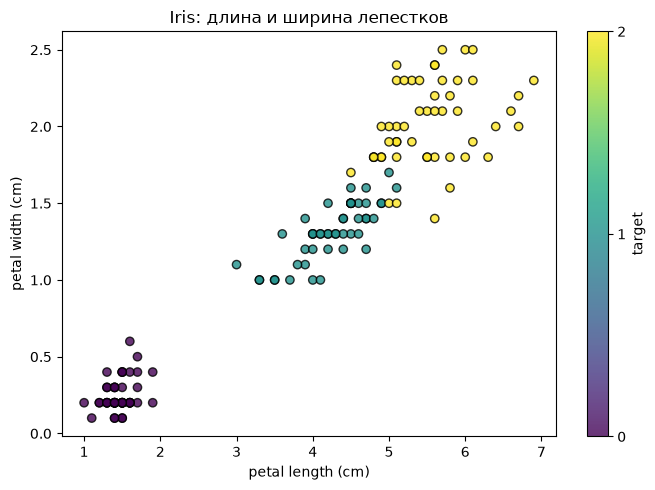

In [45]:
import io
import matplotlib.pyplot as plt
from IPython.display import display, HTML
from html import escape

fig, ax = plt.subplots(figsize=(7, 5))

points = ax.scatter(
    iris["petal length (cm)"],
    iris["petal width (cm)"],
    c=iris["target"],
    cmap="viridis",
    edgecolors="black",
    alpha=0.8,
)

ax.set_xlabel("petal length (cm)")
ax.set_ylabel("petal width (cm)")
ax.set_title("Iris: длина и ширина лепестков")

colorbar = fig.colorbar(points, ax=ax, ticks=[0, 1, 2])
colorbar.set_label("target")
fig.tight_layout()

buffer = io.BytesIO()
fig.savefig(buffer, format="png", dpi=150)

s3.put_object(
    Bucket=BUCKET,
    Key="images/iris_scatter.png",
    Body=buffer.getvalue(),
    ContentType="image/png",
)

plt.show()
plt.close(fig)

# Клиент s3 уже использует наш локальный адрес.
url = s3.generate_presigned_url(
    "get_object",
    Params={
        "Bucket": BUCKET,
        "Key": "images/iris_scatter.png",
    },
    ExpiresIn=600,
)

display(HTML(
    f'<a href="{escape(url, quote=True)}" target="_blank">'
    "Открыть график — ссылка действует 10 минут</a>"
))

### Задача 6. Модель в S3
Обучите `RandomForestClassifier(random_state=42)` на Iris, сохраните модель в `models/iris_rf.joblib`,
загрузите её обратно и посчитайте accuracy загруженной модели на всём датасете.

In [46]:
import joblib
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

X_iris = iris.drop(columns="target")
y_iris = iris["target"]

model = RandomForestClassifier(random_state=42)
model.fit(X_iris, y_iris)

# Модель → байты → S3.
buffer = io.BytesIO()
joblib.dump(model, buffer)

s3.put_object(
    Bucket=BUCKET,
    Key="models/iris_rf.joblib",
    Body=buffer.getvalue(),
)

# S3 → байты → модель.
body = s3.get_object(
    Bucket=BUCKET,
    Key="models/iris_rf.joblib",
)["Body"]

try:
    loaded_model = joblib.load(io.BytesIO(body.read()))
finally:
    body.close()

predictions = loaded_model.predict(X_iris)
accuracy = accuracy_score(y_iris, predictions)

print(f"Accuracy загруженной модели: {accuracy:.4f}")
print("Оценка выполнена на всём датасете, как требуется в задании.")

Accuracy загруженной модели: 1.0000
Оценка выполнена на всём датасете, как требуется в задании.


### Задача 7 (со звёздочкой). Резервная копия «папки»
Напишите функцию `backup(prefix)`, которая копирует **все** объекты с ключами на `prefix`
в `backup/<prefix>…` через `copy_object`. Сделайте резервную копию `reports/`,
затем удалите оригиналы из `reports/` и покажите, что копии на месте.

In [47]:
def objects_with_prefix(prefix):
    """Получить все объекты, в том числе если их больше 1000."""
    paginator = s3.get_paginator("list_objects_v2")
    return [
        obj
        for page in paginator.paginate(
            Bucket=BUCKET,
            Prefix=prefix,
        )
        for obj in page.get("Contents", [])
    ]


def backup(prefix):
    # Получаем список до копирования, чтобы не захватить новые копии.
    originals = objects_with_prefix(prefix)

    for obj in originals:
        source_key = obj["Key"]
        backup_key = f"backup/{source_key}"

        s3.copy_object(
            Bucket=BUCKET,
            Key=backup_key,
            CopySource={
                "Bucket": BUCKET,
                "Key": source_key,
            },
        )

        copied_size = s3.head_object(
            Bucket=BUCKET,
            Key=backup_key,
        )["ContentLength"]

        if copied_size != obj["Size"]:
            raise RuntimeError(
                f"Размер резервной копии не совпал: {source_key}"
            )

        print(f"{source_key} → {backup_key}")

    return [obj["Key"] for obj in originals]


# Сначала создаём все копии.
original_keys = backup("reports/")

# Если копирование завершилось успешно, удаляем оригиналы.
for key in original_keys:
    s3.delete_object(Bucket=BUCKET, Key=key)

print("\nОригиналы в reports/:")
remaining = objects_with_prefix("reports/")
for obj in remaining:
    print(obj["Key"])
if not remaining:
    print("Пусто")

print("\nРезервные копии:")
copies = objects_with_prefix("backup/reports/")
for obj in copies:
    print(obj["Key"], obj["Size"], "байт")

copy_keys = {obj["Key"] for obj in copies}

assert not remaining
assert all(f"backup/{key}" in copy_keys for key in original_keys)

print("\nПроверка пройдена: оригиналы удалены, копии сохранены.")

reports/report_1.txt → backup/reports/report_1.txt
reports/report_2.txt → backup/reports/report_2.txt
reports/report_3.txt → backup/reports/report_3.txt

Оригиналы в reports/:
Пусто

Резервные копии:
backup/reports/report_1.txt 23 байт
backup/reports/report_2.txt 23 байт
backup/reports/report_3.txt 23 байт

Проверка пройдена: оригиналы удалены, копии сохранены.


---
**Готово?** Откройте веб-консоль S3 (`http://10.162.1.86:9001/rustfs/console/index.html`),
войдите **своим логином и паролем S3** и посмотрите файлы своего бакета глазами. Дальше — Airflow: те же операции, но через `S3Hook`
и по расписанию.